In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("listrik_jakarta_sample.csv")
df.head()


,kwh,ac_units,ac_hours_per_day,family_size,month_name,tariff_class,bill_idr
0,324.9,1,0.6,6,Feb,R2,519650
1,439.7,2,4.6,4,Oct,R2,607962
2,375.4,3,1.3,6,Aug,R2,620331
3,378.1,1,1.5,5,Jun,R1,646209
4,326.2,0,6.3,5,Jun,R1,538045


# Pemeriksaan awal data

Periksa tipe data, nilai yang hilang, dan ringkasan statistik dari dataset.


In [ ]:
print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nSummary Statistics (Numeric):")
print(df.describe())

Data Types:
kwh                 float64
ac_units              int64
ac_hours_per_day    float64
family_size           int64
month_name           object
tariff_class         object
bill_idr              int64
dtype: object

Missing Values:
kwh                 0
ac_units            0
ac_hours_per_day    0
family_size         0
month_name          0
tariff_class        0
bill_idr            0
dtype: int64

Summary Statistics (Numeric):
              kwh    ac_units  ac_hours_per_day  family_size       bill_idr
count  400.000000  400.000000        400.000000   400.000000     400.000000
mean   351.165250    1.455000          5.010250     4.010000  549161.762500
std     77.032385    1.138515          2.899904     1.417718  135655.419844
min    159.300000    0.000000          0.000000     2.000000  220229.000000
25%    299.600000    0.000000          2.600000     3.000000  458961.250000
50%    349.900000    1.000000          4.900000     4.000000  540431.500000
75%    404.250000    2.000000  

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   kwh               400 non-null    float64
 1   ac_units          400 non-null    int64  
 2   ac_hours_per_day  400 non-null    float64
 3   family_size       400 non-null    int64  
 4   month_name        400 non-null    object 
 5   tariff_class      400 non-null    object 
 6   bill_idr          400 non-null    int64  
dtypes: float64(2), int64(3), object(2)
memory usage: 22.0+ KB


# Analisis variabel kategorikal


Analisis distribusi dan hubungan antara variabel kategorikal ('month_name' dan 'tariff_class') dengan 'bill_idr'.


Average Bill Amount by Month:
month_name
Apr    528893.868421
Aug    528328.689655
Dec    526224.965517
Feb    531323.116279
Jan    542666.423077
Jul    618871.343750
Jun    536439.866667
Mar    508259.535714
May    514887.851852
Nov    543910.115385
Oct    574086.380952
Sep    619950.114286
Name: bill_idr, dtype: float64

Average Bill Amount by Tariff Class:
tariff_class
R1    518336.488038
R2    561680.600000
R3    628096.737705
Name: bill_idr, dtype: float64


<Figure size 1200x600 with 0 Axes>

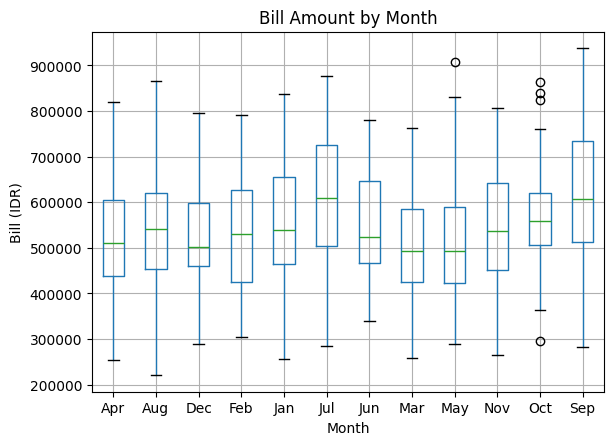

<Figure size 800x600 with 0 Axes>

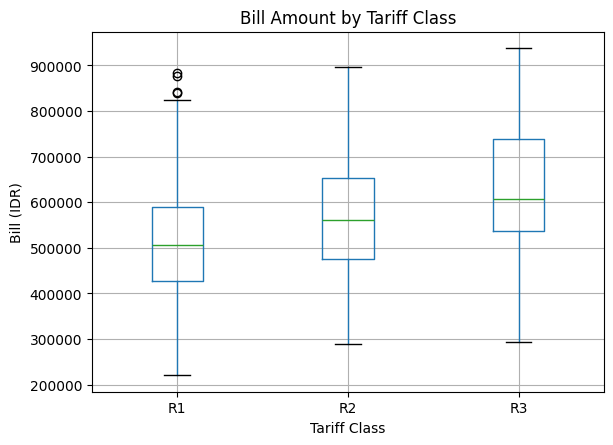

In [ ]:
avg_by_month = df.groupby('month_name')['bill_idr'].mean()
print("Average Bill Amount by Month:")
print(avg_by_month)

avg_by_tariff = df.groupby('tariff_class')['bill_idr'].mean()
print("\nAverage Bill Amount by Tariff Class:")
print(avg_by_tariff)

plt.figure(figsize=(12, 6))
df.boxplot(column='bill_idr', by='month_name')
plt.xlabel('Month')
plt.ylabel('Bill (IDR)')
plt.title('Bill Amount by Month')
plt.suptitle('') # Suppress default title
plt.show()

plt.figure(figsize=(8, 6))
df.boxplot(column='bill_idr', by='tariff_class')
plt.xlabel('Tariff Class')
plt.ylabel('Bill (IDR)')
plt.title('Bill Amount by Tariff Class')
plt.suptitle('') # Suppress default title
plt.show()

#Remove Outliers per Group (month_name)


In [ ]:
df_clean_month = pd.DataFrame()

for month in df['month_name'].unique():
    month_group = df[df['month_name'] == month]

    Q1 = month_group['bill_idr'].quantile(0.25)
    Q3 = month_group['bill_idr'].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Filter data untuk menghapus outlier dalam grup bulan ini
    filtered_month_group = month_group[(month_group['bill_idr'] >= lower_bound) & (month_group['bill_idr'] <= upper_bound)]

    df_clean_month = pd.concat([df_clean_month, filtered_month_group])

print(f"Bentuk DataFrame asli: {df.shape}")
print(f"Bentuk DataFrame setelah menghapus outlier per bulan: {df_clean_month.shape}")

Bentuk DataFrame asli: (400, 7)
Bentuk DataFrame setelah menghapus outlier per bulan: (395, 7)


In [ ]:
df_clean_tariff = pd.DataFrame()

for tariff in df['tariff_class'].unique():
    tariff_group = df[df['tariff_class'] == tariff]

    Q1 = tariff_group['bill_idr'].quantile(0.25)
    Q3 = tariff_group['bill_idr'].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Filter data to remove outliers within this tariff group
    filtered_tariff_group = tariff_group[(tariff_group['bill_idr'] >= lower_bound) & (tariff_group['bill_idr'] <= upper_bound)]

    df_clean_tariff = pd.concat([df_clean_tariff, filtered_tariff_group])

print(f"Bentuk DataFrame asli: {df.shape}")
print(f"Bentuk DataFrame setelah menghapus outlier per kelas tarif: {df_clean_tariff.shape}")

Bentuk DataFrame asli: (400, 7)
Bentuk DataFrame setelah menghapus outlier per kelas tarif: (396, 7)


Visualisasi box plot

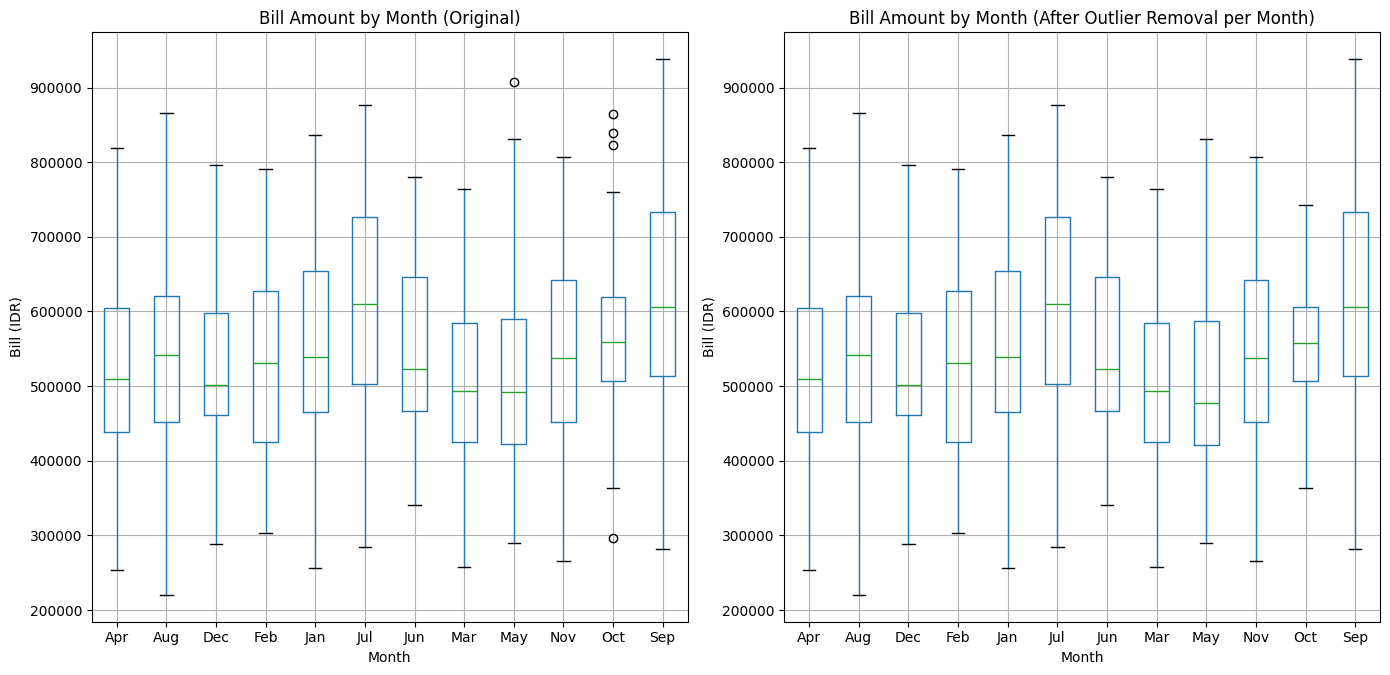

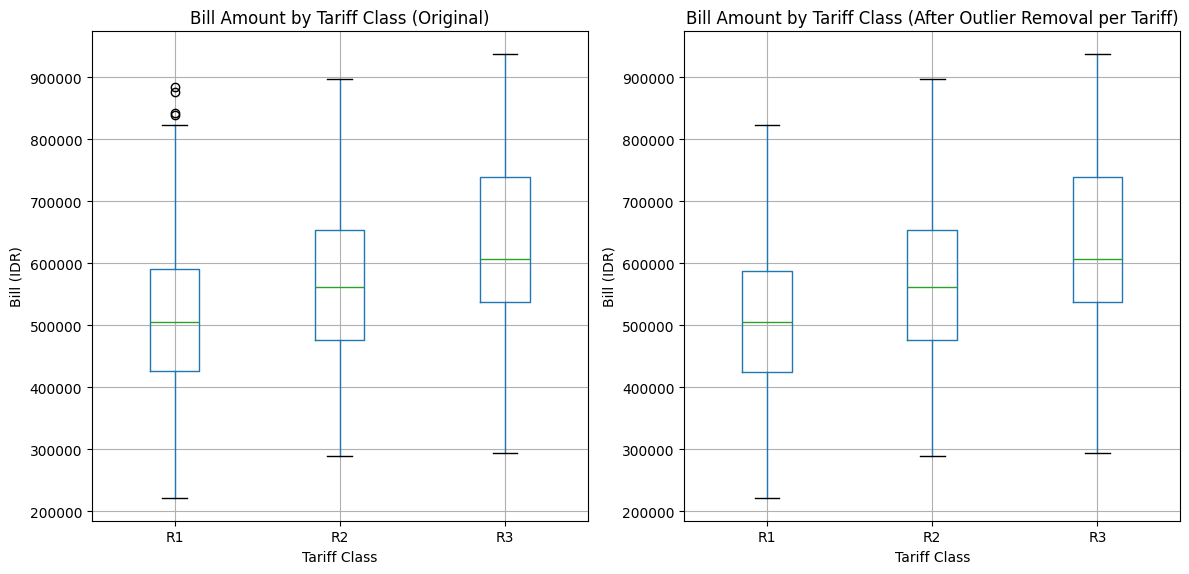

In [ ]:
import matplotlib.pyplot as plt

# Visualize 'bill_idr' distribution by 'month_name' (Before and After Outlier Removal)
plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1)
df.boxplot(column='bill_idr', by='month_name', ax=plt.gca())
plt.xlabel('Month')
plt.ylabel('Bill (IDR)')
plt.title('Bill Amount by Month (Original)')
plt.suptitle('')

plt.subplot(1, 2, 2)
df_clean_month.boxplot(column='bill_idr', by='month_name', ax=plt.gca(), showfliers=False) # Modified: Added showfliers=False
plt.xlabel('Month')
plt.ylabel('Bill (IDR)')
plt.title('Bill Amount by Month (After Outlier Removal per Month)')
plt.suptitle('')
plt.tight_layout()
plt.show()

# Visualize 'bill_idr' distribution by 'tariff_class' (Before and After Outlier Removal)
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
df.boxplot(column='bill_idr', by='tariff_class', ax=plt.gca())
plt.xlabel('Tariff Class')
plt.ylabel('Bill (IDR)')
plt.title('Bill Amount by Tariff Class (Original)')
plt.suptitle('')

plt.subplot(1, 2, 2)
df_clean_tariff.boxplot(column='bill_idr', by='tariff_class', ax=plt.gca(), showfliers=False) # Modified: Added showfliers=False
plt.xlabel('Tariff Class')
plt.ylabel('Bill (IDR)')
plt.title('Bill Amount by Tariff Class (After Outlier Removal per Tariff)')
plt.suptitle('')
plt.tight_layout()
plt.show()

Membuat DataFrame Bersih Gabungan

Untuk mendapatkan DataFrame yang bersih dari pencilan berdasarkan kedua kriteria ('month_name' dan 'tariff_class'), kita akan mengambil irisan (intersection) dari indeks baris yang tersisa setelah penghapusan outlier per bulan dan per kelas tarif.

In [ ]:
common_indices = df_clean_month.index.intersection(df_clean_tariff.index)
df_clean_combined = df.loc[common_indices]

print(f"Bentuk DataFrame asli: {df.shape}")
print(f"Bentuk DataFrame setelah menghapus outlier per bulan DAN per kelas tarif: {df_clean_combined.shape}")

Bentuk DataFrame asli: (400, 7)
Bentuk DataFrame setelah menghapus outlier per bulan DAN per kelas tarif: (392, 7)


# Analisis variabel numerik


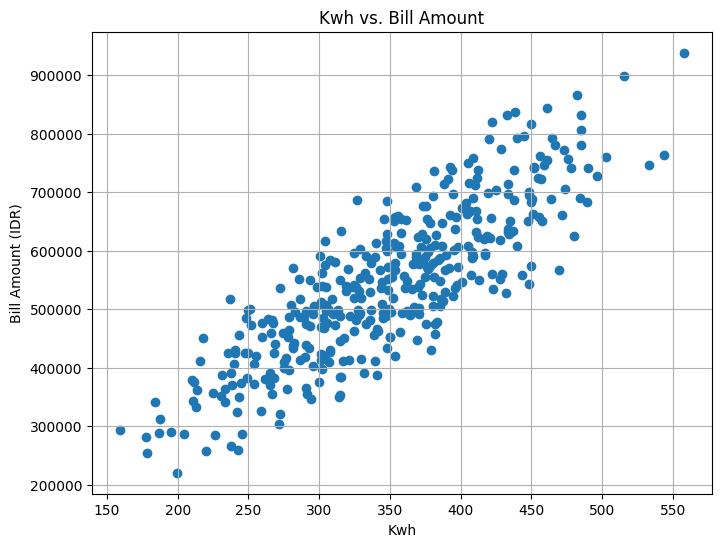

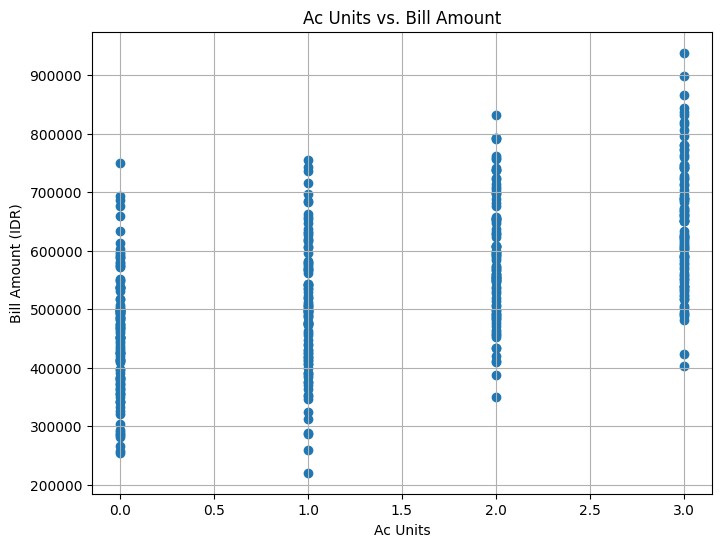

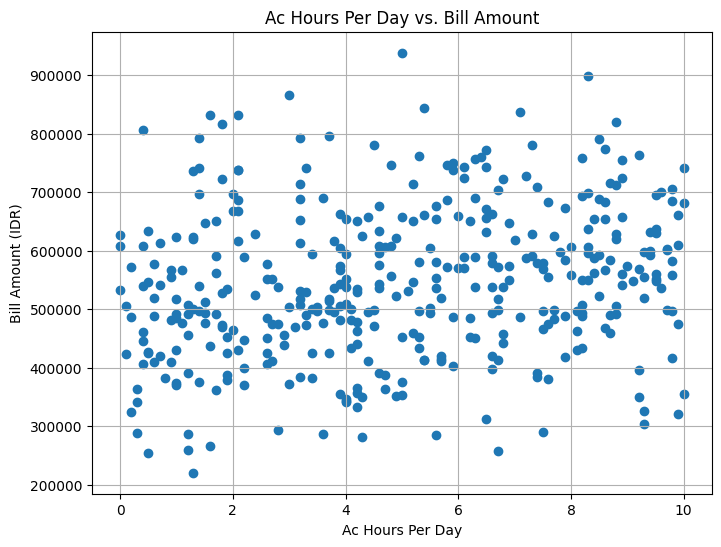

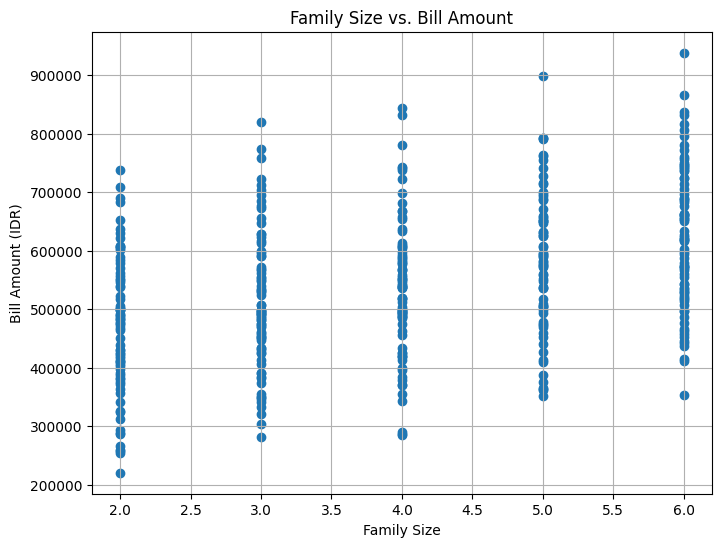

In [ ]:
numerical_cols = ['kwh', 'ac_units', 'ac_hours_per_day', 'family_size']
target_col = 'bill_idr'

for col in numerical_cols:
    plt.figure(figsize=(8, 6))
    plt.scatter(df_clean_combined[col], df_clean_combined[target_col])
    plt.xlabel(col.replace('_', ' ').title())
    plt.ylabel('Bill Amount (IDR)')
    plt.title(f'{col.replace("_", " ").title()} vs. Bill Amount')
    plt.grid(True)
    plt.show()



# Analisis korelasi

Hitung dan visualisasikan korelasi antar variabel numerik.



Correlation Matrix:
                       kwh  ac_units  ac_hours_per_day  family_size  bill_idr
kwh               1.000000  0.628451          0.276046     0.488591  0.845267
ac_units          0.628451  1.000000          0.020439     0.037393  0.557277
ac_hours_per_day  0.276046  0.020439          1.000000     0.030547  0.210105
family_size       0.488591  0.037393          0.030547     1.000000  0.408205
bill_idr          0.845267  0.557277          0.210105     0.408205  1.000000


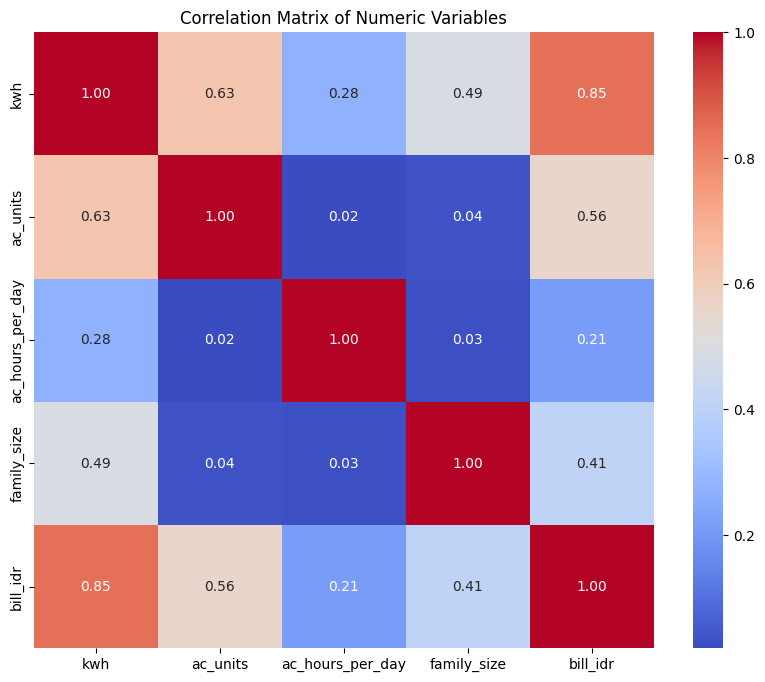

In [ ]:
import seaborn as sns

correlation_matrix = df_clean_combined[numerical_cols + [target_col]].corr()
print("\nCorrelation Matrix:")
print(correlation_matrix)

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numeric Variables')
plt.show()

# Prepare Data for Modeling

Memisahkan data menjadi training dan testing


In [ ]:
from sklearn.model_selection import train_test_split

# 1. Pisahkan fitur (X) dan target (y)
X = df_clean_combined.drop('bill_idr', axis=1)
y = df_clean_combined['bill_idr']

# 2. Terapkan one-hot encoding pada kolom kategorikal
X = pd.get_dummies(X, columns=['month_name', 'tariff_class'], drop_first=True)

# 3. Bagi data menjadi set pelatihan dan pengujian
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)
#print("\nFirst 5 rows of X_train (after encoding):\n", X_train.head())

Shape of X_train: (313, 17)
Shape of X_test: (79, 17)
Shape of y_train: (313,)
Shape of y_test: (79,)


## Linear Regression



In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Inisialisasi model LinearRegression
linear_model = LinearRegression()

# Latih model menggunakan X_train dan y_train
linear_model.fit(X_train, y_train)

# Lakukan prediksi pada X_test
y_pred_lr = linear_model.predict(X_test)

# Hitung dan cetak metrik evaluasi
r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)

print("Linear Regression Model Performance:")
print(f"R-squared: {r2_lr:.4f}")
print(f"Mean Absolute Error (MAE): {mae_lr:.2f}")
print(f"Mean Squared Error (MSE): {mse_lr:.2f}")

Linear Regression Model Performance:
R-squared: 0.7881
Mean Absolute Error (MAE): 47906.78
Mean Squared Error (MSE): 3347721098.84


## Decision Tree Regressor


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Inisialisasi model DecisionTreeRegressor
dtr_model = DecisionTreeRegressor(random_state=42)

# Latih model menggunakan X_train dan y_train
dtr_model.fit(X_train, y_train)

# Lakukan prediksi pada X_test
y_pred_dtr = dtr_model.predict(X_test)

# Hitung dan cetak metrik evaluasi
r2_dtr = r2_score(y_test, y_pred_dtr)
mae_dtr = mean_absolute_error(y_test, y_pred_dtr)
mse_dtr = mean_squared_error(y_test, y_pred_dtr)

print("Decision Tree Regressor Model Performance:")
print(f"R-squared: {r2_dtr:.4f}")
print(f"Mean Absolute Error (MAE): {mae_dtr:.2f}")
print(f"Mean Squared Error (MSE): {mse_dtr:.2f}")

Decision Tree Regressor Model Performance:
R-squared: 0.6684
Mean Absolute Error (MAE): 59698.23
Mean Squared Error (MSE): 5237730489.82


## Random Forest Regressor


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Inisialisasi model RandomForestRegressor
rfr_model = RandomForestRegressor(random_state=42)

# Latih model menggunakan X_train dan y_train
rfr_model.fit(X_train, y_train)

# Lakukan prediksi pada X_test
y_pred_rfr = rfr_model.predict(X_test)

# Hitung dan cetak metrik evaluasi
r2_rfr = r2_score(y_test, y_pred_rfr)
mae_rfr = mean_absolute_error(y_test, y_pred_rfr)
mse_rfr = mean_squared_error(y_test, y_pred_rfr)

print("Random Forest Regressor Model Performance:")
print(f"R-squared: {r2_rfr:.4f}")
print(f"Mean Absolute Error (MAE): {mae_rfr:.2f}")
print(f"Mean Squared Error (MSE): {mse_rfr:.2f}")

Random Forest Regressor Model Performance:
R-squared: 0.7329
Mean Absolute Error (MAE): 53989.56
Mean Squared Error (MSE): 4219097804.49


## Gradient Boosting Regressor


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Inisialisasi model GradientBoostingRegressor
gbr_model = GradientBoostingRegressor(random_state=42)

# Latih model menggunakan X_train dan y_train
gbr_model.fit(X_train, y_train)

# Lakukan prediksi pada X_test
y_pred_gbr = gbr_model.predict(X_test)

# Hitung dan cetak metrik evaluasi
r2_gbr = r2_score(y_test, y_pred_gbr)
mae_gbr = mean_absolute_error(y_test, y_pred_gbr)
mse_gbr = mean_squared_error(y_test, y_pred_gbr)

print("Gradient Boosting Regressor Model Performance:")
print(f"R-squared: {r2_gbr:.4f}")
print(f"Mean Absolute Error (MAE): {mae_gbr:.2f}")
print(f"Mean Squared Error (MSE): {mse_gbr:.2f}")

Gradient Boosting Regressor Model Performance:
R-squared: 0.7495
Mean Absolute Error (MAE): 53579.18
Mean Squared Error (MSE): 3956869425.46


## K-Nearest Neighbors (KNN) Regressor


In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Inisialisasi model KNeighborsRegressor
knn_model = KNeighborsRegressor()

# Latih model menggunakan X_train dan y_train
knn_model.fit(X_train, y_train)

# Lakukan prediksi pada X_test
y_pred_knn = knn_model.predict(X_test)

# Hitung dan cetak metrik evaluasi
r2_knn = r2_score(y_test, y_pred_knn)
mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)

print("K-Nearest Neighbors Regressor Model Performance:")
print(f"R-squared: {r2_knn:.4f}")
print(f"Mean Absolute Error (MAE): {mae_knn:.2f}")
print(f"Mean Squared Error (MSE): {mse_knn:.2f}")

K-Nearest Neighbors Regressor Model Performance:
R-squared: 0.6064
Mean Absolute Error (MAE): 63743.44
Mean Squared Error (MSE): 6218004458.91


In [ ]:
import pandas as pd

# Create a dictionary to store model performance
model_performance = {
    'Model': ['Linear Regression', 'Decision Tree Regressor', 'Random Forest Regressor', 'Gradient Boosting Regressor', 'K-Nearest Neighbors Regressor'],
    'R-squared': [r2_lr, r2_dtr, r2_rfr, r2_gbr, r2_knn],
    'MAE': [mae_lr, mae_dtr, mae_rfr, mae_gbr, mae_knn],
    'MSE': [mse_lr, mse_dtr, mse_rfr, mse_gbr, mse_knn]
}

# Convert to DataFrame
performance_df = pd.DataFrame(model_performance)

# Sort by R-squared in descending order to easily identify the best model
performance_df = performance_df.sort_values(by='R-squared', ascending=False)

print("\nModel Performance Comparison:")
print(performance_df.to_string(index=False))

print(f"\nThe best performing model based on R-squared is: {performance_df.iloc[0]['Model']}")


Model Performance Comparison:
                        Model  R-squared          MAE          MSE
            Linear Regression   0.788079 47906.779538 3.347721e+09
  Gradient Boosting Regressor   0.749518 53579.184256 3.956869e+09
      Random Forest Regressor   0.732918 53989.562532 4.219098e+09
      Decision Tree Regressor   0.668436 59698.227848 5.237730e+09
K-Nearest Neighbors Regressor   0.606381 63743.443038 6.218004e+09

The best performing model based on R-squared is: Linear Regression


# Analisis Overfitting (Evaluasi pada Data Pelatihan)

Untuk mendeteksi overfitting, kita akan membandingkan kinerja model pada data pelatihan dan data pengujian. Perbedaan yang signifikan (kinerja jauh lebih baik di data pelatihan daripada data pengujian) dapat mengindikasikan overfitting.

In [ ]:
# --- Linear Regression --- #
y_pred_lr_train = linear_model.predict(X_train)
r2_lr_train = r2_score(y_train, y_pred_lr_train)
mae_lr_train = mean_absolute_error(y_train, y_pred_lr_train)
mse_lr_train = mean_squared_error(y_train, y_pred_lr_train)

# --- Decision Tree Regressor --- #
y_pred_dtr_train = dtr_model.predict(X_train)
r2_dtr_train = r2_score(y_train, y_pred_dtr_train)
mae_dtr_train = mean_absolute_error(y_train, y_pred_dtr_train)
mse_dtr_train = mean_squared_error(y_train, y_pred_dtr_train)

# --- Random Forest Regressor --- #
y_pred_rfr_train = rfr_model.predict(X_train)
r2_rfr_train = r2_score(y_train, y_pred_rfr_train)
mae_rfr_train = mean_absolute_error(y_train, y_pred_rfr_train)
mse_rfr_train = mean_squared_error(y_train, y_pred_rfr_train)

# --- Gradient Boosting Regressor --- #
y_pred_gbr_train = gbr_model.predict(X_train)
r2_gbr_train = r2_score(y_train, y_pred_gbr_train)
mae_gbr_train = mean_absolute_error(y_train, y_pred_gbr_train)
mse_gbr_train = mean_squared_error(y_train, y_pred_gbr_train)

# --- K-Nearest Neighbors Regressor --- #
y_pred_knn_train = knn_model.predict(X_train)
r2_knn_train = r2_score(y_train, y_pred_knn_train)
mae_knn_train = mean_absolute_error(y_train, y_pred_knn_train)
mse_knn_train = mean_squared_error(y_train, y_pred_knn_train)

# Create a dictionary to store training performance
training_performance = {
    'Model': ['Linear Regression', 'Decision Tree Regressor', 'Random Forest Regressor', 'Gradient Boosting Regressor', 'K-Nearest Neighbors Regressor'],
    'R-squared (Train)': [r2_lr_train, r2_dtr_train, r2_rfr_train, r2_gbr_train, r2_knn_train],
    'MAE (Train)': [mae_lr_train, mae_dtr_train, mae_rfr_train, mae_gbr_train, mae_knn_train],
    'MSE (Train)': [mse_lr_train, mse_dtr_train, mse_rfr_train, mse_gbr_train, mse_knn_train]
}

training_performance_df = pd.DataFrame(training_performance)

# Merge with test performance for comparison
comparison_df = pd.merge(training_performance_df, performance_df, on='Model', suffixes=('_train', '_test'))

# Calculate the difference in R-squared
comparison_df['Diff (R-squared)'] = comparison_df['R-squared (Train)'] - comparison_df['R-squared']

print("\nModel Performance Comparison (Train vs Test):")
print(comparison_df.to_string(index=False))


Model Performance Comparison (Train vs Test):
                        Model  R-squared (Train)  MAE (Train)  MSE (Train)  R-squared          MAE          MSE  Diff (R-squared)
            Linear Regression           0.798187 45808.774785 3.368841e+09   0.788079 47906.779538 3.347721e+09          0.010108
      Decision Tree Regressor           1.000000     0.000000 0.000000e+00   0.668436 59698.227848 5.237730e+09          0.331564
      Random Forest Regressor           0.959896 20798.930799 6.694524e+08   0.732918 53989.562532 4.219098e+09          0.226978
  Gradient Boosting Regressor           0.912171 30062.958874 1.466113e+09   0.749518 53579.184256 3.956869e+09          0.162653
K-Nearest Neighbors Regressor           0.775657 50457.242812 3.744933e+09   0.606381 63743.443038 6.218004e+09          0.169276
